# Fitting a phonon DOS with Gaussian peaks

This tutorial shows how to describe a phonon density of states (DOS) as a small set of Gaussian peaks with `singingmaterials.peak_fitting`, and how to save those peaks to a CSV file. The peaks (their frequencies, heights and widths) provide a compact summary of the spectrum, which can be useful for sonification. For example: each peak can become a note, with its height setting the loudness and its width the spread of the sound.

In [1]:
from singingmaterials import peak_fitting, visualisation
import numpy as np

## 1. The model

Each peak is a symmetric Gaussian with height $h$, centre $f_0$ and full width at half maximum $w$:

$$g(f) = h \exp\left(-4\ln 2 \, \frac{(f-f_0)^2}{w^2}\right)$$

and the fit is the sum of the peaks. 

The fit works in three steps:

1. **Find candidate positions.** The DOS is smoothed with a Gaussian of width `smoothing` (THz). The candidate peaks are identified as the maxima of the curvature ($-d^2g/df^2$). Smoothing stops noise in the data from being identified as a candidate peak.
2. **Choose peaks one at a time.** Each new peak goes to the candidate where the current fit leaves the most DOS unexplained. This ensures that a broad region that has no peak yet is preferred over a sharp feature right next to an existing peak.
3. **Fit the widths.** Each peak's centre is fixed at its candidate position and its height at the DOS there. The widths are fitted by least squares. Fixing the centres and heights keeps every peak on a real feature of the DOS, so the peaks are easy to interpret.

## 2. Fit the total dos of diamond (mp-66)

`fit_dos_peaks` returns a dict of fits. To fit the total DOS use the key `"total"`.

Fetching from existing file...
total: 7 Gaussian peaks (from 8 candidates, smoothing 0.3 THz). DOS integral 6.000, fitted 6.129
  Peak 1: Center = 16.416 THz, Amplitude = 0.1375, FWHM = 5.906 THz, Integrated Modes = 0.86
  Peak 2: Center = 23.072 THz, Amplitude = 0.1992, FWHM = 7.060 THz, Integrated Modes = 1.50
  Peak 3: Center = 30.357 THz, Amplitude = 0.2421, FWHM = 3.399 THz, Integrated Modes = 0.88
  Peak 4: Center = 32.545 THz, Amplitude = 0.1894, FWHM = 0.243 THz, Integrated Modes = 0.05
  Peak 5: Center = 34.704 THz, Amplitude = 0.4690, FWHM = 2.059 THz, Integrated Modes = 1.03
  Peak 6: Center = 36.982 THz, Amplitude = 0.8734, FWHM = 1.664 THz, Integrated Modes = 1.55
  Peak 7: Center = 39.290 THz, Amplitude = 0.3773, FWHM = 0.665 THz, Integrated Modes = 0.27


<Axes: title={'center': 'Phonon DOS fit (mp-66)'}, xlabel='Frequency (THz)', ylabel='Phonon DOS (states / THz)'>

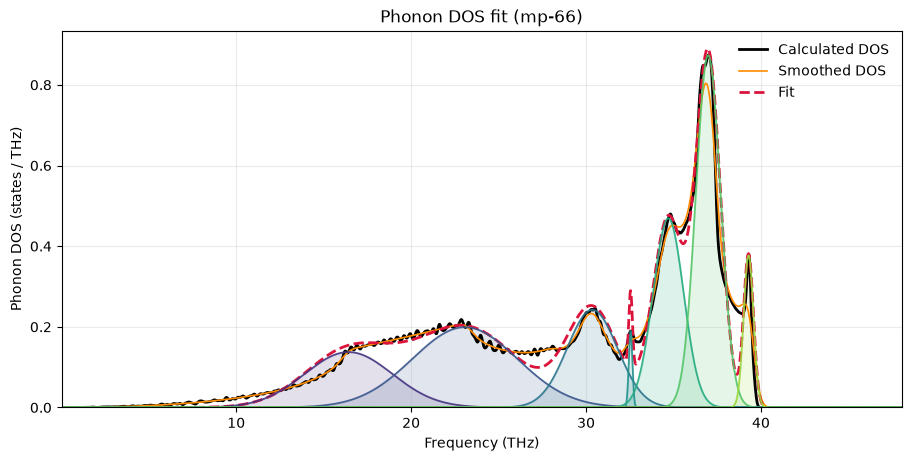

In [2]:
fits = peak_fitting.fit_dos_peaks("mp-66", n_peaks=7, smoothing=0.3)
fit = fits["total"]
peak_fitting.print_peak_fit(fit)
visualisation.plot_peak_fit(fit)

The plot shows the DOS (black), the smoothed DOS used to find the peaks (orange), the fit (red dashed) and each peak (shaded). 

The fit is a dict, so you can use the numbers directly. Frequencies and widths are in Hz.

In [3]:
print("centres (THz):", fit["centres"] / 1e12)
print("heights:      ", fit["heights"])
print("FWHMs (THz):  ", fit["fwhms"] / 1e12)
print("modes in each peak:", fit["modes"])

centres (THz): [16.41620867 23.07160123 30.35655796 32.54504291 34.7035486  36.98197129
 39.29037321]
heights:       [0.13746645 0.19919919 0.24214433 0.1893612  0.46901683 0.87337941
 0.37730889]
FWHMs (THz):   [5.90632119 7.06003979 3.39896066 0.24269625 2.05942061 1.66414922
 0.66526695]
modes in each peak: [0.86426315 1.49701768 0.87609793 0.04891998 1.0281718  1.54713221
 0.26719308]


## 3. Choosing `smoothing`

`smoothing` sets which features become candidate peaks; a smaller value picks up finer structure but can also lead to noise being identified as a peak. 

Calcite (mp-3953, CaCO$_3$) has very sharp peaks from the vibrations inside the carbonate ion, and fine structure below 10 THz. Compare two smoothing values with the same 9 peaks:

Fetching from existing file...
smoothing 0.3 THz: peaks at [ 3.7  5.5  6.7  8.7 20.6 25.1 32.3 42.7 45.1] THz, residual sum of squares 89
Fetching from existing file...
smoothing 0.1 THz: peaks at [ 3.7  5.3  5.7  6.8  8.8 20.6 25.1 32.3 42.8] THz, residual sum of squares 142


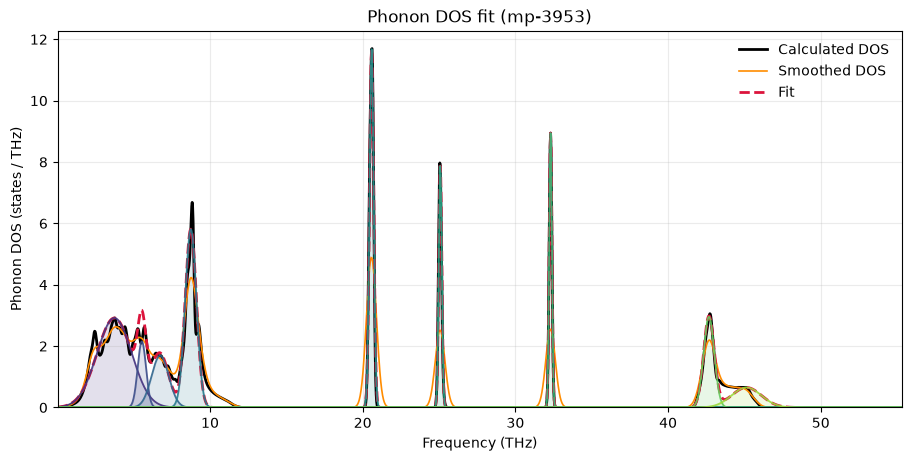

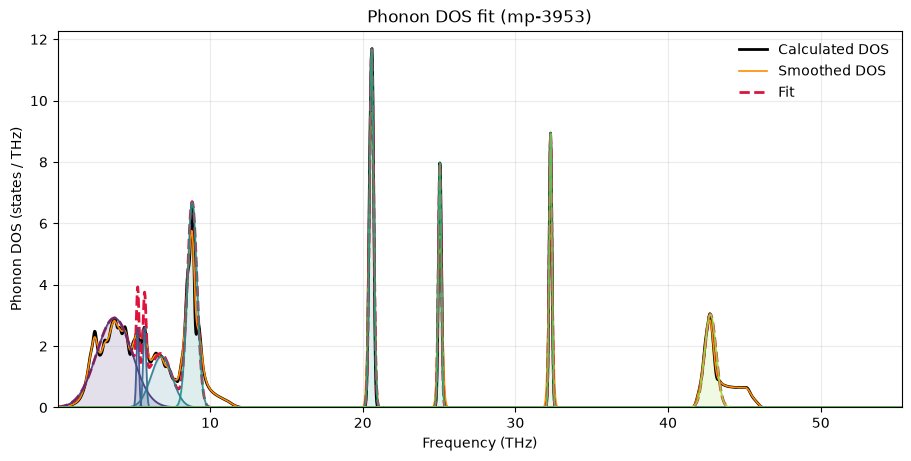

In [4]:
for smoothing in [0.3, 0.1]:
    fit_s = peak_fitting.fit_dos_peaks("mp-3953", n_peaks=9, smoothing=smoothing)["total"]
    sse = np.sum(fit_s["residuals"] ** 2)
    print(f"smoothing {smoothing} THz: peaks at {np.round(fit_s['centres'] / 1e12, 1)} THz, "
          f"residual sum of squares {sse:.0f}")
    visualisation.plot_peak_fit(fit_s)

### Settings for our prototype materials

For the three materials used here, these settings give a good fit. Silica (mp-6947, SiO$_2$) is a third example, with many overlapping features between 8 and 31 THz:

| Material | `n_peaks` | `smoothing` (THz) |
|---|---|---|
| diamond (mp-66) | 7 | 0.3 |
| calcite (mp-3953) | 9 | 0.3 |
| silica (mp-6947) | 7 | 0.3 |

Fetching from existing file...
total: 7 Gaussian peaks (from 12 candidates, smoothing 0.3 THz). DOS integral 18.000, fitted 17.994
  Peak 1: Center = 10.211 THz, Amplitude = 1.2222, FWHM = 3.098 THz, Integrated Modes = 4.03
  Peak 2: Center = 12.999 THz, Amplitude = 1.9610, FWHM = 0.912 THz, Integrated Modes = 1.90
  Peak 3: Center = 14.647 THz, Amplitude = 0.9848, FWHM = 1.657 THz, Integrated Modes = 1.74
  Peak 4: Center = 16.626 THz, Amplitude = 1.1530, FWHM = 1.328 THz, Integrated Modes = 1.63
  Peak 5: Center = 20.373 THz, Amplitude = 1.1859, FWHM = 4.127 THz, Integrated Modes = 5.21
  Peak 6: Center = 24.421 THz, Amplitude = 1.0726, FWHM = 1.171 THz, Integrated Modes = 1.34
  Peak 7: Center = 27.239 THz, Amplitude = 0.8029, FWHM = 2.510 THz, Integrated Modes = 2.15


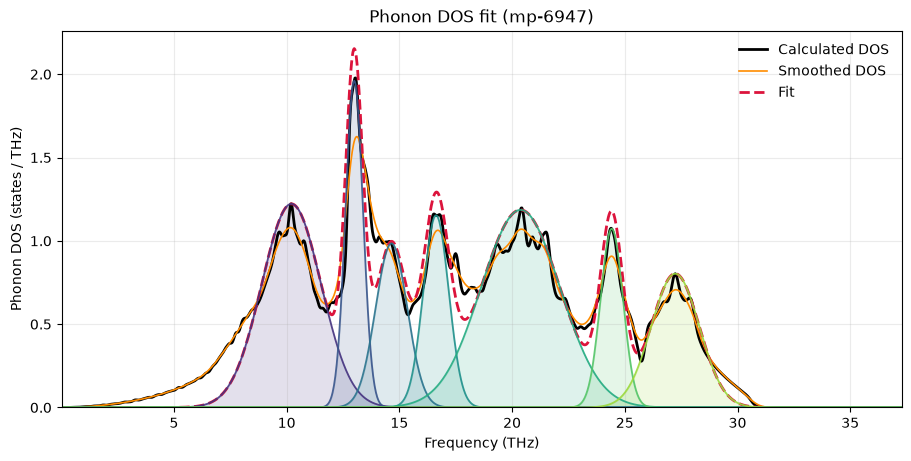

In [5]:
fit = peak_fitting.fit_dos_peaks("mp-6947", n_peaks=7, smoothing=0.3)["total"]
peak_fitting.print_peak_fit(fit)
visualisation.plot_peak_fit(fit);

## 4. Fitting the projected DOS

With `projection="element"`, each element's PDOS is fitted separately (the PDOS of all sites of the same element are summed first). `projection="site"` fits each site instead.

`n_peaks` and `smoothing` can be a single value for every element, or a dict by element. Elements missing from a dict use the defaults (9 peaks, 0.3 THz). In calcite, calcium's fine low-frequency structure is fitted best with less smoothing, while carbon and oxygen do better with the default, so only calcium's smoothing is changed:

In [8]:
fits_el = peak_fitting.fit_dos_peaks("mp-3953", projection="element",
                                     n_peaks={"Ca": 6, "C": 5, "O": 6}, smoothing={"Ca": 0.1})
for fit_el in fits_el.values():
    peak_fitting.print_peak_fit(fit_el)

Fetching from existing file...
Ca: 6 Gaussian peaks (from 14 candidates, smoothing 0.1 THz). DOS integral 6.000, fitted 5.790
  Peak 1: Center = 2.446 THz, Amplitude = 0.7176, FWHM = 1.063 THz, Integrated Modes = 0.81
  Peak 2: Center = 3.645 THz, Amplitude = 0.8468, FWHM = 0.060 THz, Integrated Modes = 0.05
  Peak 3: Center = 4.095 THz, Amplitude = 0.8585, FWHM = 1.609 THz, Integrated Modes = 1.47
  Peak 4: Center = 6.823 THz, Amplitude = 1.0337, FWHM = 1.958 THz, Integrated Modes = 2.15
  Peak 5: Center = 8.831 THz, Amplitude = 2.3643, FWHM = 0.404 THz, Integrated Modes = 1.02
  Peak 6: Center = 9.311 THz, Amplitude = 0.7713, FWHM = 0.343 THz, Integrated Modes = 0.28
C: 5 Gaussian peaks (from 8 candidates, smoothing 0.3 THz). DOS integral 6.000, fitted 5.252
  Peak 1: Center = 8.712 THz, Amplitude = 0.3106, FWHM = 1.111 THz, Integrated Modes = 0.37
  Peak 2: Center = 20.583 THz, Amplitude = 0.8874, FWHM = 0.323 THz, Integrated Modes = 0.30
  Peak 3: Center = 25.080 THz, Amplitude = 6

`plot_peak_fits` shows the projections as stacked panels with a shared frequency axis, each with its own y-axis so small projections stay readable. 

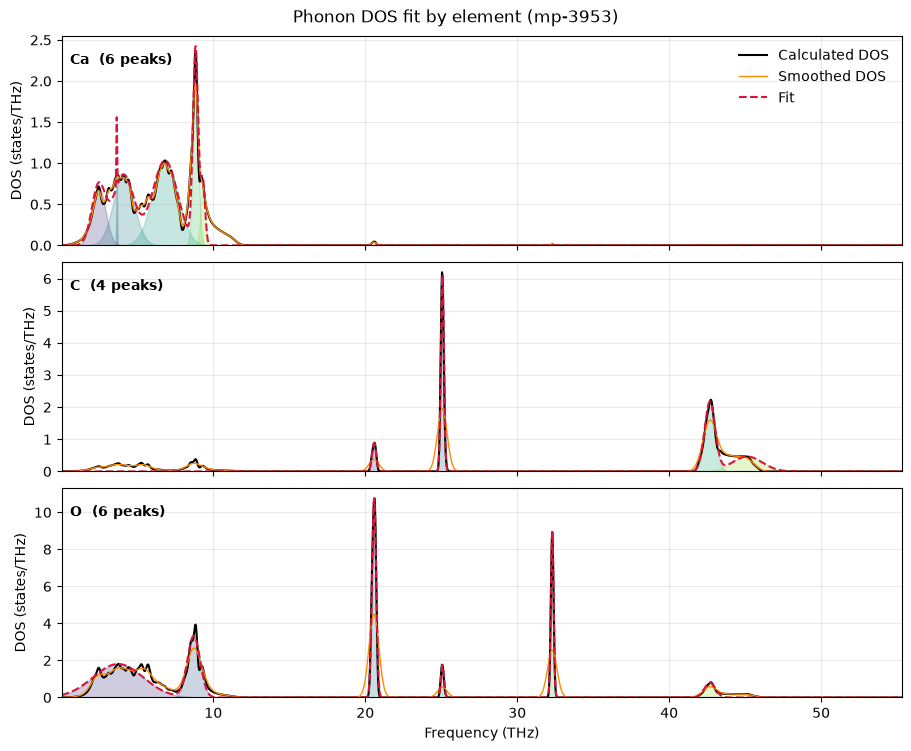

In [7]:
visualisation.plot_peak_fits(fits_el);

## 5. Saving the peaks

`save_peak_fit` writes one row per peak. The frequency and FWHM are in Hz. The ratios are relative to the tallest peak: the DOS ratio is each height divided by the tallest height, the normalised DOS ratio is the DOS ratios scaled to sum to 1, and the frequency ratio is each centre divided by the tallest peak's centre.

For a projected fit there is also a `Species` column, and the ratios are taken relative to the tallest peak across all species, so the species are on the same scale.

In [21]:
filename = peak_fitting.save_peak_fit(fits_el)  # default name: peak_fit_{mp_id}_{projection}.csv
print(filename)

import pandas as pd
pd.read_csv(filename, comment="#")

peak_fit_mp-3953_element.csv


# projection: element, temperature: athermal, smoothing: 0.1, 0.3 THz, frequencies in Hz
Species Peak Index Peak Height        Frequency          FWHM               DOS Ratio           Normalized DOS Ratio                                    Frequency Ratio                                      
Ca      81         0.7176003906879593 2445880124072.59   1063455799750.5918 0.06679684182573868 0.01647522158810944                                 0.11882823901075573                                      
        121        0.8467713953294271 3645049956072.8433 59958491600.01267  0.07882054649127833 0.019440828842289835                                0.17708752899351568                                      
        136        0.8584984797829751 4094738643072.9375 1609241199647.2463 0.0799121459601272  0.019710068265040775                                0.19893476273705063                                      
        227        1.0336811836694442 6822850010873.517  1958236681524.9265 0.09621878613752648 0.023732047492458393                                 0.3314746474478297                                      
        294        2.3642580541417813 8831459479473.94   404171497480.1831  0.22007369746041464 0.05428045446869887                                  0.4290589581689525                                      
        310        0.7712734391943783 9311127412274.04   342825810390.691   0.07179292345823525 0.017707488709097                                    0.4523626741620564                                      
C       686        0.8873561760641338 20583323833076.42  322836817352.16455 0.08259832478466739 0.02037260544718842                                                 1.0                                      
        836        6.109152416051652  25080210703077.37  237885154236.9341  0.5686620198647261  0.14025861896966485                                  1.2184723374353499                                      
        1423       2.159129832688329  42678027987681.09  821686004494.9456  0.20097962011566095 0.04957096302154334                                  2.0734274179323524                                      
        1505       0.463963338488649  45136326143281.62  2317221135812.6323 0.04318738693028969 0.010652027102481587                                 2.1928589623970103                                      
O       124        1.8094606866396428 3734987693472.8623 3860979191095.1504 0.16843115032237782 0.041542989878783215                                 0.1814569757422227                                      
        290        3.3132641252213655 8711542496273.914  983631681052.844   0.30841061762401223 0.07606846561304624                                  0.4232330291706765                                      
        686        10.74302872821523  20583323833076.42  323070286657.10486 1.0                 0.24664671469184757                                                 1.0                                      
        836        1.7529408362929588 25080210703077.37  238254427113.62152 0.16317007807017006 0.04024536369201973                                  1.2184723374353499                                      
        1077       8.931400207749476  32305208940878.9   210073004203.33255 0.8313670598582934  0.20505395401706866                                  1.5694845595814786                                      
        1423       0.794562993267793  42678027987681.09  863965153570.8118  0.07396079945136627 0.018242188200662094                                 2.0734274179323524

## 6. Finite-temperature DOS

The DOS counts the phonon modes at each frequency, but at a finite temperature not all modes are equally excited. The number of phonons in a mode of frequency $f$ is given by the Bose-Einstein occupation

$$n(f, T) = \frac{1}{e^{hf/k_BT} - 1}$$

and weighting the DOS by it, $g(f)\,n(f,T)$, gives the phonon distribution at temperature $T$. Modes with $hf \ll k_BT$ are strongly occupied, and modes with $hf \gg k_BT$ are almost totally unoccupied. The weighted DOS no longer integrates to $3N$.

The lowest few points of a calculated DOS hold a small tail from the smearing of the modes at zero frequency, where the DOS should fall to zero as $f^2$. The occupation grows as $k_BT/hf$ when $f \to 0$, so after weighting that tail becomes a spike. `min_frequency=0.5` leaves the frequencies below 0.5 THz out of the fit. 

Fetching from existing file...
total at 300 K: 6 Gaussian peaks (from 15 candidates, smoothing 0.5 THz). DOS integral 0.165, fitted 0.172
  Peak 1: Center = 4.874 THz, Amplitude = 0.0041, FWHM = 4.671 THz, Integrated Modes = 0.02
  Peak 2: Center = 9.251 THz, Amplitude = 0.0050, FWHM = 4.823 THz, Integrated Modes = 0.03
  Peak 3: Center = 16.506 THz, Amplitude = 0.0113, FWHM = 6.862 THz, Integrated Modes = 0.08
  Peak 4: Center = 22.952 THz, Amplitude = 0.0055, FWHM = 4.244 THz, Integrated Modes = 0.03
  Peak 5: Center = 30.267 THz, Amplitude = 0.0019, FWHM = 5.699 THz, Integrated Modes = 0.01
  Peak 6: Center = 36.862 THz, Amplitude = 0.0024, FWHM = 3.111 THz, Integrated Modes = 0.01
Fetching from existing file...
total at 1000 K: 6 Gaussian peaks (from 6 candidates, smoothing 0.5 THz). DOS integral 2.489, fitted 2.450
  Peak 1: Center = 16.536 THz, Amplitude = 0.1231, FWHM = 7.032 THz, Integrated Modes = 0.92
  Peak 2: Center = 22.952 THz, Amplitude = 0.1058, FWHM = 5.257 THz, Integr

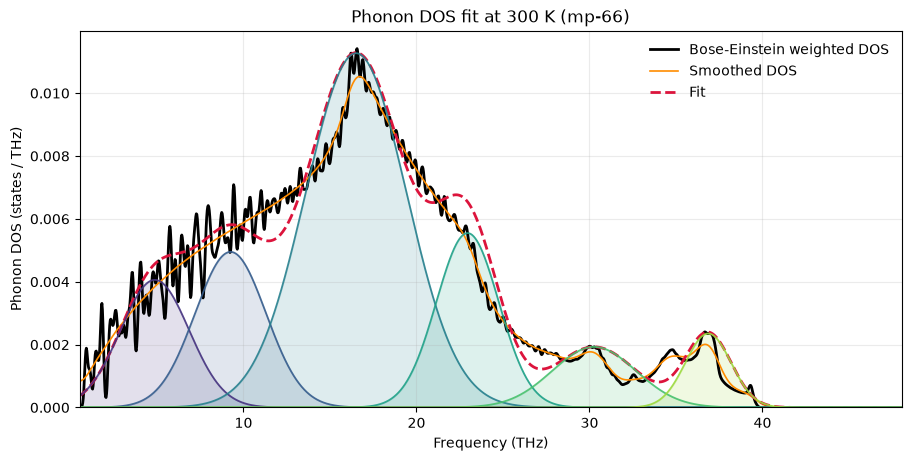

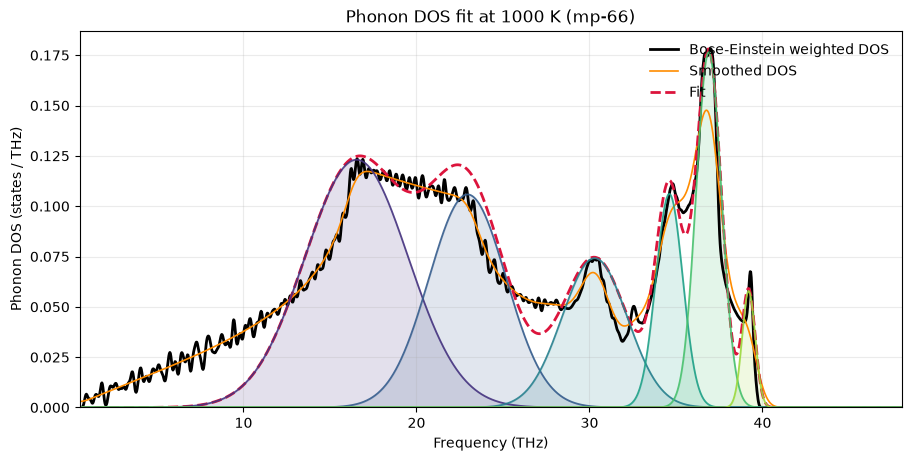

In [10]:
for T in [300, 1000]:
    fit_T = peak_fitting.fit_dos_peaks("mp-66", n_peaks=6, smoothing=0.5, temperature=T, min_frequency=0.5)["total"]
    peak_fitting.print_peak_fit(fit_T)
    visualisation.plot_peak_fit(fit_T)

### Projected DOS at finite temperature

Fetching from existing file...
peak_fit_mp-3953_element_300K.csv
"# projection: element, temperature: 300K, smoothing: 0.1, 0.3 THz, frequencies in Hz"



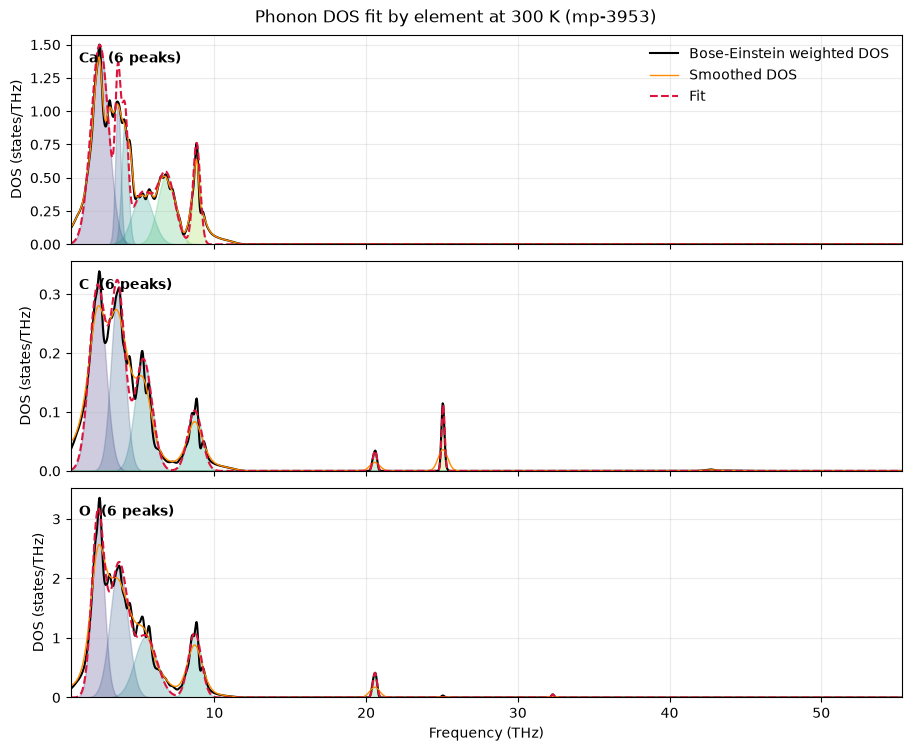

In [11]:
fits_el_300 = peak_fitting.fit_dos_peaks("mp-3953", projection="element", n_peaks={"Ca": 6, "C": 6, "O": 6},
                                         smoothing={"Ca": 0.1}, temperature=300, min_frequency=0.5)
visualisation.plot_peak_fits(fits_el_300)

filename = peak_fitting.save_peak_fit(fits_el_300)  # -> peak_fit_mp-3953_element_300K.csv
print(filename)
print(open(filename).readlines()[1])

## 7. Other data sources (beyond materials project)

`fit_dos_peaks` also accepts a `dos_dict` instead of an `mp_id`. To fit any single DOS curve, call `fit_peaks` with the frequencies (Hz) and densities directly:

```python
fit = peak_fitting.fit_peaks(frequencies_hz, densities, n_peaks=6, smoothing=0.3)
```
